In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df.head()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df.info()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df.info()

In [ ]:
df["Churn"].value_counts()

In [ ]:
df["Churn"].value_counts(normalize=True) * 100

In [ ]:
df["TotalCharges"].head(10)

In [ ]:
type(df["TotalCharges"].iloc[0])

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [ ]:
df["TotalCharges"].dtype

In [ ]:
df["TotalCharges"].isna().sum()

In [ ]:
df[df["TotalCharges"].isna()]

In [ ]:
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [ ]:
df["TotalCharges"].isna().sum()

In [ ]:
df.describe()

In [ ]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean()

In [ ]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

In [ ]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100

In [ ]:
pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100

In [ ]:
df.groupby("Churn")["tenure"].describe()

In [ ]:
import matplotlib.pyplot as plt

df.boxplot(column="tenure", by="Churn")

plt.title("Tenure Distribution by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

In [ ]:
df.isna().sum()

In [ ]:
df["Contract"].unique()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [ ]:
churn_rate = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

churn_rate

In [ ]:
df.groupby("Churn")["MonthlyCharges"].describe()

In [ ]:
df["tenure"].head(10)


In [ ]:
df.groupby("Churn")["tenure"].mean()


In [ ]:
df.groupby("Churn")["tenure"].median()

In [ ]:
df.groupby("Churn")["MonthlyCharges"].describe()

In [ ]:
df.groupby("Churn")["MonthlyCharges"].mean()

In [ ]:
df.groupby("Churn")["TotalCharges"].describe()

In [ ]:
pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100

In [ ]:
pd.crosstab(df["TechSupport"], df["Churn"], normalize="index") * 100

In [ ]:
pd.crosstab(df["OnlineSecurity"], df["Churn"], normalize="index") * 100

In [ ]:
df.groupby("Churn")["MonthlyCharges"].describe()

In [ ]:
pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100

In [ ]:
pd.crosstab(df["PaperlessBilling"], df["Churn"], normalize="index") * 100

In [ ]:
pd.crosstab(df["SeniorCitizen"], df["Churn"], normalize="index") * 100

In [86]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

print(X.shape)
print(y.shape)

(7043, 20)
(7043,)


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

In [ ]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

In [ ]:
X_train.dtypes

In [ ]:
X_train = X_train.drop("customerID", axis=1)
X_test = X_test.drop("customerID", axis=1)

In [ ]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

print("\nNumber of numeric columns:", len(numeric_features))
print("Number of categorical columns:", len(categorical_features))

In [ ]:
print("X_train exists:", "X_train" in globals())
print([name for name in globals() if "train" in name.lower()])

In [ ]:
X_train = X_train.drop(columns=["customerID"])
X_test = X_test.drop(columns=["customerID"])

print("customerID in X_train:", "customerID" in X_train.columns)
print("customerID in X_test:", "customerID" in X_test.columns)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

In [80]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [81]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [83]:
from sklearn.linear_model import LogisticRegression

In [84]:
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [85]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

In [ ]:
model.predict_proba(X_test)

In [ ]:
print(y_prob[:10, 1])

In [ ]:
y_prob = model.predict_proba(X_test)

print(y_prob[:10, 1])

In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred_threshold = np.where(y_prob[:, 1] >= threshold, "Yes", "No")
    
    precision = precision_score(y_test, y_pred_threshold, pos_label="Yes")
    recall = recall_score(y_test, y_pred_threshold, pos_label="Yes")
    f1 = f1_score(y_test, y_pred_threshold, pos_label="Yes")
    
    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall:    {recall:.2f}")
    print(f"F1:        {f1:.2f}")
    print()

In [ ]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob[:, 1])

print("ROC-AUC:", auc)

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob[:, 1],
    pos_label="Yes"
)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

In [ ]:
y_pred_rf = rf_model.predict(X_test)

print(classification_report(y_test, y_pred_rf))

In [ ]:
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_rf = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob_rf
)

print("Random Forest ROC-AUC:", roc_auc_rf)

In [ ]:
threshold = 0.3

y_pred_03 = (y_prob[:, 1] >= threshold).astype(int)

y_pred_03 = np.where(y_pred_03 == 1, "Yes", "No")

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_03))

In [ ]:
print(confusion_matrix(y_test, y_pred_03))

In [ ]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

In [ ]:
print(rf_model.named_steps)

In [ ]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = rf_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

In [ ]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Random Forest")

plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_test_binary = (y_test == "Yes").astype(int)

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    y_pred_threshold = (y_prob[:, 1] >= threshold).astype(int)

    precision = precision_score(y_test_binary, y_pred_threshold)
    recall = recall_score(y_test_binary, y_pred_threshold)
    f1 = f1_score(y_test_binary, y_pred_threshold)

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision:.2f} | "
        f"Recall: {recall:.2f} | "
        f"F1: {f1:.2f}"
    )

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

threshold = 0.3

y_pred_03 = (y_prob[:, 1] >= threshold).astype(int)

print(confusion_matrix(y_test_binary, y_pred_03))

In [ ]:
print(classification_report(
    y_test_binary,
    y_pred_03,
    target_names=["No", "Yes"]
))

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test_binary,
    y_prob[:, 1]
)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test_binary, y_prob[:, 1])

# Random Forest
y_prob_rf = rf_model.predict_proba(X_test)
fpr_rf, tpr_rf, _ = roc_curve(y_test_binary, y_prob_rf[:, 1])

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label="Logistic Regression (AUC = 0.842)")
plt.plot(fpr_rf, tpr_rf, label="Random Forest (AUC = 0.822)")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

In [ ]:
final_threshold = 0.3

final_predictions = (y_prob[:, 1] >= final_threshold).astype(int)

print(final_predictions[:20])

In [ ]:
import joblib

joblib.dump(model, "churn_model.pkl")

print("Model saved successfully!")

In [ ]:
loaded_model = joblib.load("churn_model.pkl")

print("Model loaded successfully!")

In [ ]:
def predict_churn(customer_data, threshold=0.3):
    probability = loaded_model.predict_proba(customer_data)[0, 1]

    prediction = "Yes" if probability >= threshold else "No"

    return {
        "churn_probability": probability,
        "prediction": prediction
    }

In [ ]:
result = predict_churn(X_test.iloc[[0]])

print(result)

In [ ]:
new_customer = pd.DataFrame([{
    "SeniorCitizen": 0,
    "gender": "Male",
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 85.0,
    "TotalCharges": 170.0
}])

result = predict_churn(new_customer)

print(result)

In [ ]:
import joblib

joblib.dump(rf_model, "churn_model.pkl")

In [ ]:
loaded_model = joblib.load("churn_model.pkl")

prediction = loaded_model.predict(X_test)

print(prediction[:10])

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Pretvaramo Yes/No u 1/0
y_test_binary = (y_test == "Yes").astype(int)

# ROC podaci
fpr, tpr, thresholds = roc_curve(y_test_binary, y_prob[:, 1])

# AUC
auc = roc_auc_score(y_test_binary, y_prob[:, 1])

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds_pr = precision_recall_curve(
    y_test_binary,
    y_prob[:, 1]
)

ap = average_precision_score(
    y_test_binary,
    y_prob[:, 1]
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Logistic Regression (AP = {ap:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.show()

In [ ]:
final_threshold = 0.30

y_pred_final = (
    y_prob[:, 1] >= final_threshold
).astype(int)

print(classification_report(
    y_test_binary,
    y_pred_final
))

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_binary, y_pred_final)

print(cm)

In [ ]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Threshold 0.30")

plt.show()

In [ ]:
import joblib

joblib.dump(model, "churn_model.pkl")

In [ ]:
loaded_model = joblib.load("churn_model.pkl")

print(loaded_model)

In [ ]:
def predict_churn(customer):
    probability = loaded_model.predict_proba(customer)[0, 1]

    prediction = "Yes" if probability >= 0.30 else "No"

    return {
        "churn_probability": probability,
        "prediction": prediction
    }

In [ ]:
customer = X_test.iloc[[1]]

result = predict_churn(customer)

print(result)

In [ ]:
joblib.dump(model, "churn_model.pkl")

In [ ]:
from sklearn.model_selection import train_test_split

print("train_test_split je uspješno učitan!")

In [ ]:
%pip install scikit-learn

In [ ]:
from sklearn.model_selection import train_test_split

print("Import uspješan!")

In [87]:
print("Model je istreniran:", hasattr(model, "classes_"))
print("Klase:", model.classes_ if hasattr(model, "classes_") else "Model još nije istreniran")

Model je istreniran: True
Klase: ['No' 'Yes']


In [88]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8055358410220014

Classification report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



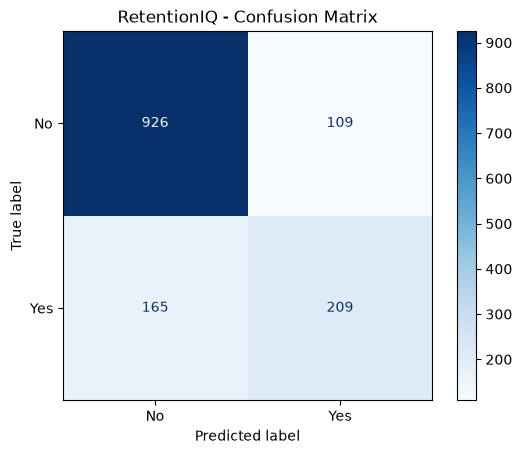

In [94]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["No", "Yes"],
    cmap="Blues"
)

plt.title("RetentionIQ - Confusion Matrix")
plt.show()

In [91]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\irhad\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [95]:
from sklearn.metrics import classification_report

y_prob = model.predict_proba(X_test)[:, 1]
y_pred_30 = (y_prob >= 0.30).astype(int)

print(classification_report(
    y_test.map({"No": 0, "Yes": 1}),
    y_pred_30,
    target_names=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.89      0.75      0.81      1035
         Yes       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [96]:
%pip install xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 6.9 MB/s eta 0:00:08
   -- ------------------------------------- 2.6/48.9 MB 8.7 MB/s eta 0:00:06
   --- ------------------------------------ 4.5/48.9 MB 8.8 MB/s eta 0:00:06
   ----- ---------------------------------- 6.6/48.9 MB 8.8 MB/s eta 0:00:05
   ------ --------------------------------- 8.1/48.9 MB 8.7 MB/s eta 0:00:05
   -------- ------------------------------- 10.0/48.9 MB 8.7 MB/s eta 0:00:05
   --------- ------------------------------ 11.8/48.9 MB 8.8 MB/s eta 0:00:05
   ----------- ---------------------------- 13.6/48.9 MB 8.8 MB/s eta 0:00:04
   ------------ --------------------------- 15.5/48.9 MB 8.7 MB/s eta 0:00:04
   ------------- -------------------------- 16.5/48.9 MB 8.5 MB/s eta 0:00:04
   -------------- ------------------------- 17.6/48.9 MB 8.1 MB/s eta 0:00:04
   -------------- ------------------------- 18.4/48.9 MB 7.8 MB/s eta 0:00:04


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\irhad\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [98]:
from xgboost import XGBClassifier

print("XGBoost je spreman!")

XGBoost je spreman!


In [99]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            random_state=42,
            eval_metric="logloss"
        ))
    ]
)

print("XGBoost model je pripremljen!")

XGBoost model je pripremljen!


In [100]:
xgb_model.fit(X_train, y_train)

print("XGBoost je uspješno istreniran!")

ValueError: Invalid classes inferred from unique values of `y`.  Expected: [0 1], got ['No' 'Yes']

In [101]:
y_train_xgb = y_train.map({"No": 0, "Yes": 1})
y_test_xgb = y_test.map({"No": 0, "Yes": 1})

print(y_train_xgb.value_counts())
print("\nNedostajuće vrijednosti:", y_train_xgb.isna().sum())

Churn
0    4139
1    1495
Name: count, dtype: int64

Nedostajuće vrijednosti: 0


In [102]:
xgb_model.fit(X_train, y_train_xgb)

print("XGBoost je uspješno istreniran!")

XGBoost je uspješno istreniran!


In [103]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test_xgb, y_pred_xgb))
print("\nClassification Report:")
print(classification_report(
    y_test_xgb,
    y_pred_xgb,
    target_names=["No", "Yes"]
))

XGBoost Accuracy: 0.8005677785663591

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.65      0.53      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



In [104]:
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

y_pred_xgb_30 = (y_prob_xgb >= 0.30).astype(int)

print(classification_report(
    y_test_xgb,
    y_pred_xgb_30,
    target_names=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.90      0.76      0.82      1035
         Yes       0.53      0.76      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



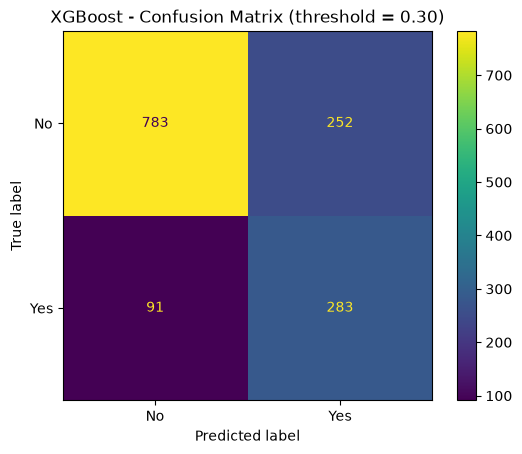

In [105]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_xgb,
    y_pred_xgb_30,
    display_labels=["No", "Yes"],
    values_format="d"
)

plt.title("XGBoost - Confusion Matrix (threshold = 0.30)")
plt.show()

XGBoost ROC-AUC: 0.8405


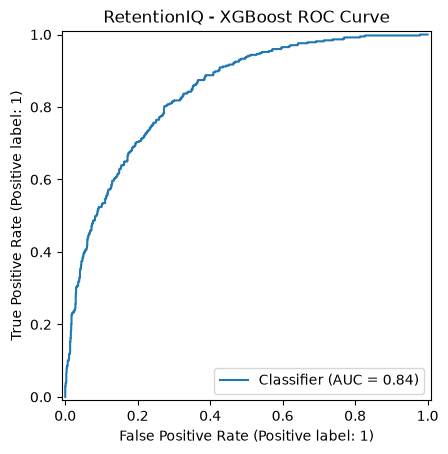

In [107]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test_xgb, y_prob_xgb)
print("XGBoost ROC-AUC:", round(auc, 4))

RocCurveDisplay.from_predictions(y_test_xgb, y_prob_xgb)
plt.title("RetentionIQ - XGBoost ROC Curve")
plt.show()

In [108]:
from sklearn.metrics import roc_auc_score

# Vjerovatnoće odlaska za Logistic Regression
y_prob_lr = model.predict_proba(X_test)[:, 1]

# Vjerovatnoće odlaska za XGBoost
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# ROC-AUC oba modela
auc_lr = roc_auc_score(y_test_xgb, y_prob_lr)
auc_xgb = roc_auc_score(y_test_xgb, y_prob_xgb)

print("Logistic Regression ROC-AUC:", round(auc_lr, 4))
print("XGBoost ROC-AUC:", round(auc_xgb, 4))

Logistic Regression ROC-AUC: 0.8421
XGBoost ROC-AUC: 0.8405


C:\Users\irhad\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_ranking.py:1364: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


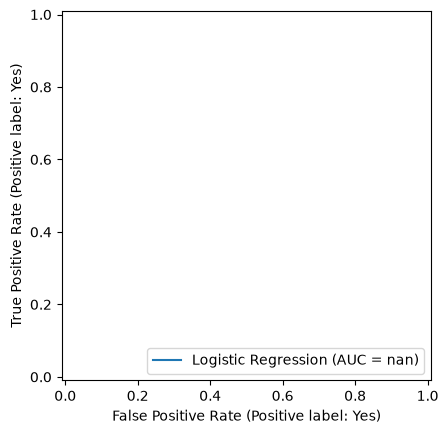

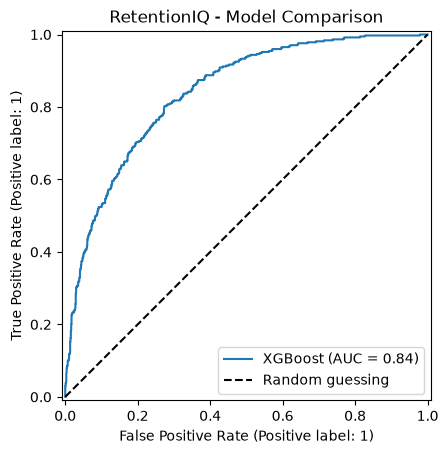

In [109]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# ROC kriva za Logistic Regression
RocCurveDisplay.from_estimator(
    model,
    X_test,
    y_test_xgb,
    name="Logistic Regression"
)

# Dodaj ROC krivu za XGBoost na isti grafikon
RocCurveDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test_xgb,
    name="XGBoost"
)

plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.title("RetentionIQ - Model Comparison")
plt.legend()
plt.show()

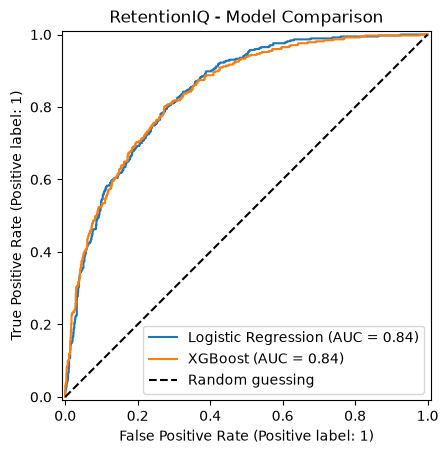

In [110]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

RocCurveDisplay.from_predictions(
    y_test_xgb,
    y_prob_lr,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test_xgb,
    y_prob_xgb,
    name="XGBoost",
    ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random guessing")
ax.set_title("RetentionIQ - Model Comparison")
ax.legend()

plt.show()

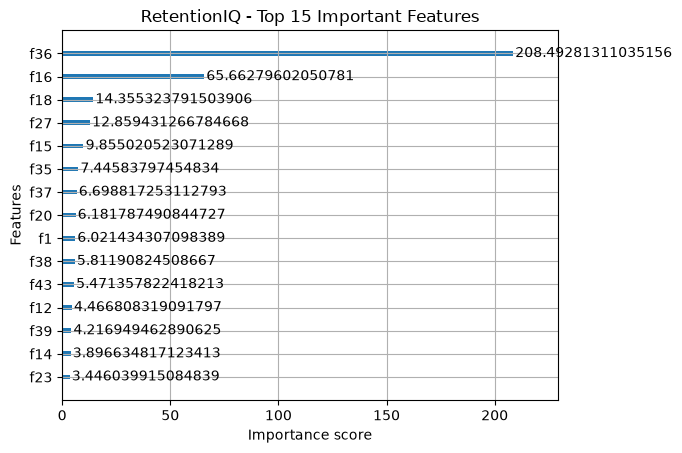

In [111]:
from xgboost import plot_importance
import matplotlib.pyplot as plt

xgb_classifier = xgb_model.named_steps["classifier"]

plot_importance(
    xgb_classifier,
    max_num_features=15,
    importance_type="gain"
)

plt.title("RetentionIQ - Top 15 Important Features")
plt.show()

In [112]:
from xgboost import plot_importance
import pandas as pd

xgb_classifier = xgb_model.named_steps["classifier"]

importance = pd.Series(
    xgb_classifier.feature_importances_,
    index=xgb_model.named_steps["preprocessor"].get_feature_names_out()
).sort_values(ascending=False)

print(importance.head(15).round(4).to_string())

cat__Contract_Month-to-month           0.5128
cat__InternetService_Fiber optic       0.1615
cat__OnlineSecurity_No                 0.0353
cat__TechSupport_No                    0.0316
cat__InternetService_DSL               0.0242
cat__StreamingMovies_Yes               0.0183
cat__Contract_One year                 0.0165
cat__OnlineSecurity_Yes                0.0152
num__tenure                            0.0148
cat__Contract_Two year                 0.0143
cat__PaymentMethod_Electronic check    0.0135
cat__MultipleLines_No                  0.0110
cat__PaperlessBilling_No               0.0104
cat__MultipleLines_Yes                 0.0096
cat__OnlineBackup_Yes                  0.0085


In [113]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


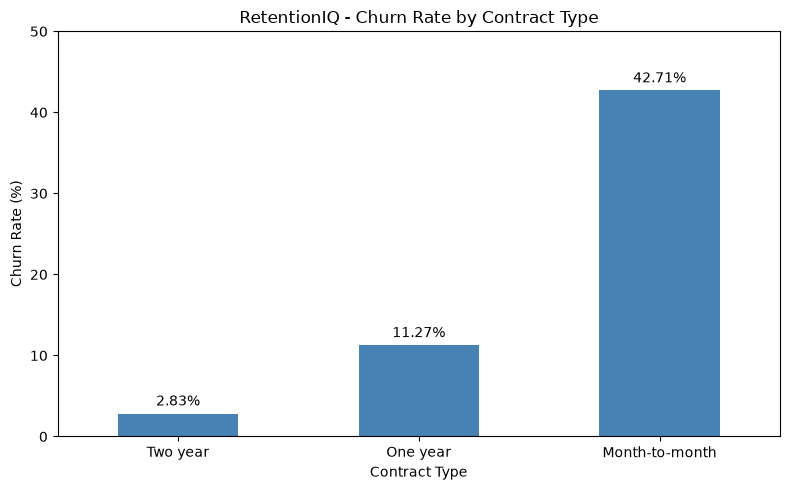

In [114]:
import matplotlib.pyplot as plt

churn_rates = churn_by_contract["Yes"].sort_values()

ax = churn_rates.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

ax.set_title("RetentionIQ - Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)

for i, value in enumerate(churn_rates):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [115]:
%pip install joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\irhad\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [116]:
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

print("Folder za modele:", models_dir.resolve())

Folder za modele: C:\Users\irhad\RetentionIQ\models


In [117]:
import joblib

joblib.dump(model, models_dir / "logistic_regression.joblib")
joblib.dump(xgb_model, models_dir / "xgboost_model.joblib")

print("Modeli su sačuvani!")

Modeli su sačuvani!


In [118]:
lr_loaded = joblib.load(
    models_dir / "logistic_regression.joblib"
)

xgb_loaded = joblib.load(
    models_dir / "xgboost_model.joblib"
)

print("Logistic Regression:", lr_loaded.named_steps["classifier"])
print("XGBoost:", xgb_loaded.named_steps["classifier"])

Logistic Regression: LogisticRegression(max_iter=1000)
XGBoost: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)
